# Polyhedral Freeze Audit — S2
Pregunta: ¿un soporte singular factible implica familia positiva? Mismo juego u_i=a_i(theta+alpha*a_j-c), dos tipos por prestamista. Cada patrón define producto de dos poliedros bidimensionales. Vértices y dimensión se calculan con Fraction; no con el rango de ecuaciones redundantes.

In [1]:
import csv,json
from pathlib import Path
for row in csv.DictReader(Path('results/summary.csv').open()): print(row)
print(json.loads(Path('results/metadata.json').read_text()))

{'scenario': 'regular', 'maximal_cells': '5', 'dimensions': '0;0;0;0;0', 'max_dimension': '0', 'total_cell_vertices': '5', 'old_status': 'isolated_list', 'old_isolated_count': '5'}
{'scenario': 'coordination_family', 'maximal_cells': '3', 'dimensions': '0;0;2', 'max_dimension': '2', 'total_cell_vertices': '6', 'old_status': 'degenerate_rejected', 'old_isolated_count': '-1'}
{'scenario': 'full_indifference', 'maximal_cells': '1', 'dimensions': '4', 'max_dimension': '4', 'total_cell_vertices': '16', 'old_status': 'degenerate_rejected', 'old_isolated_count': '-1'}
{'scenario': 'singular_but_isolated', 'maximal_cells': '2', 'dimensions': '0;0', 'max_dimension': '0', 'total_cell_vertices': '2', 'old_status': 'degenerate_rejected', 'old_isolated_count': '-1'}
{'date': '2026-10-15', 'seed': 20261015, 'support_patterns': 81, 'base_commit': 'afcbc7facb17485786c02e539759afc31b5d23fd', 'python': '3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]', 'platform': 'Linux-6.18.44-x86_64-with-glibc2

En el caso q=.5,c=.9,alpha=.8: cada prestamista puede elegir cualquier punto del segmento x(0)+x(1)=1. Su producto tiene dimensión 2; también existen dos puntos aislados. La familia no equivale a una distribución de selección ni a mecanismos observables distintos.

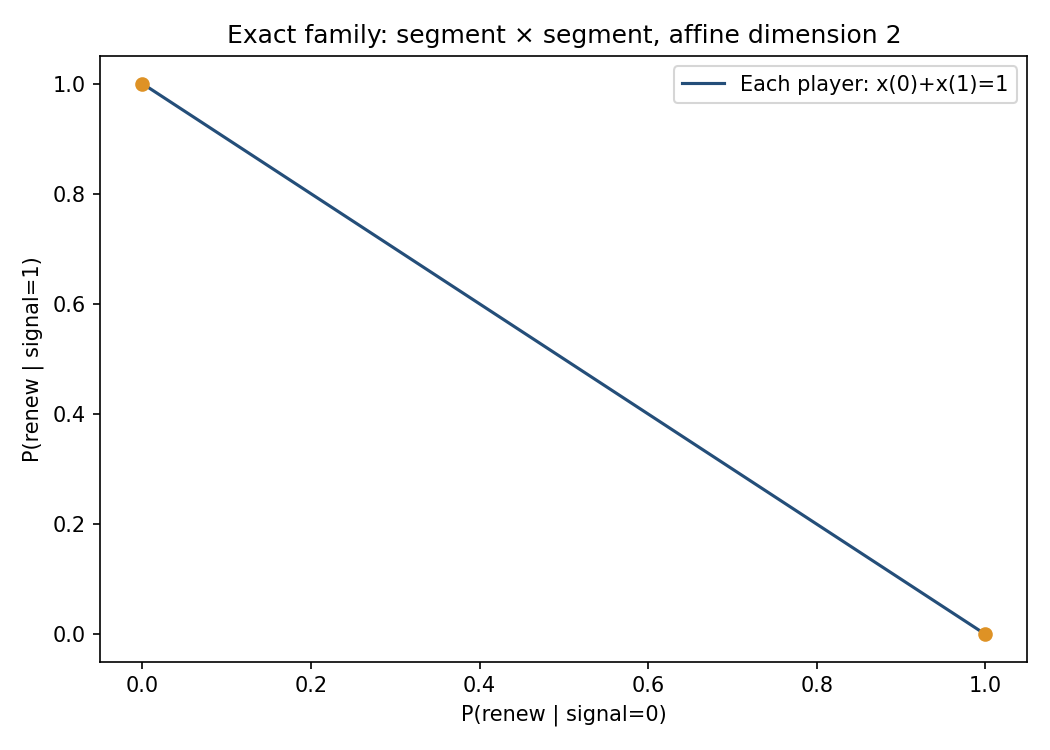

In [2]:
from IPython.display import Image,display
display(Image(filename='results/family.png'))

In [3]:
print(Path('results/coverage.txt').read_text())
print(Path('results/lp_oracle.csv').read_text()[:2500])

Name               Stmts   Miss Branch BrPart  Cover   Missing
--------------------------------------------------------------
src/__init__.py        0      0      0      0   100%
src/polyhedra.py     105      0     34      0   100%
--------------------------------------------------------------
TOTAL                105      0     34      0   100%

case,own,other,direction,status,error,exact_dimension
0,"(2, 1)","(1, 2)","(1.0, 0.0)",both_empty,0.0,-1
0,"(2, 1)","(1, 2)","(0.0, 1.0)",both_empty,0.0,-1
0,"(2, 1)","(1, 2)","(1.0, 1.0)",both_empty,0.0,-1
0,"(2, 1)","(1, 2)","(-1.0, 2.0)",both_empty,0.0,-1
1,"(1, 2)","(2, 0)","(1.0, 0.0)",both_feasible,0.0,1
1,"(1, 2)","(2, 0)","(0.0, 1.0)",both_feasible,0.0,1
1,"(1, 2)","(2, 0)","(1.0, 1.0)",both_feasible,0.0,1
1,"(1, 2)","(2, 0)","(-1.0, 2.0)",both_feasible,0.0,1
2,"(2, 0)","(2, 2)","(1.0, 0.0)",both_empty,0.0,-1
2,"(2, 0)","(2, 2)","(0.0, 1.0)",both_empty,0.0,-1
2,"(2, 0)","(2, 2)","(1.0, 1.0)",both_empty,0.0,-1
2,"(2, 0)","(2, 2)","(-1.0

## Desarrollo semanal: mecanismo, sensibilidad y controles

Las celdas nuevas recalculan experimentos específicos. Las salidas históricas anteriores se conservan como evidencia separada y no sustituyen esta ejecución.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
SEED=20261018


### Singularidad no equivale a dimensión positiva
Las igualdades de indiferencia pueden ser redundantes o incompatibles con las desigualdades. La dimensión se obtiene del espacio afín de los vértices factibles; el rango de las ecuaciones por sí solo no determina la geometría de la solución.

En q=0.5, c=0.9 y α=0.8 aparece un producto de segmentos x₁(0)+x₁(1)=1 y x₂(0)+x₂(1)=1. Perturbar q puede romper la familia sin que desaparezcan equilibrios.

In [5]:
from src.polyhedra import Game,equilibrium_cells,exact_regret
from fractions import Fraction as F
poly_rows=[]
for accuracy in [.5,.500000001,.500001,.51,.8]:
    g=Game(accuracy=accuracy,cost=.9,complementarity=.8);cells=equilibrium_cells(g)
    assert all(exact_regret(g,v)==0 for cell in cells for v in cell.vertices)
    poly_rows.append(dict(accuracy=accuracy,cells=len(cells),max_dimension=max(c.dimension for c in cells),
        vertices=sum(len(c.vertices) for c in cells)))
display(pd.DataFrame(poly_rows))
g=Game(accuracy=.5,cost=.9,complementarity=.8);cells=equilibrium_cells(g)
family=max(cells,key=lambda c:c.dimension)
assert family.dimension==2


,accuracy,cells,max_dimension,vertices
0,0.500000,3,2,6
1,0.500000,5,0,5
2,0.500001,5,0,5
3,0.510000,5,0,5
4,0.800000,5,0,5


### Interiores de la familia con fracciones exactas
Se generan 121 puntos interiores o de frontera del producto de segmentos. Verificar sus incentivos no demuestra completitud, pero sí contrasta que la geometría almacenada contiene soluciones, además de sus vértices.

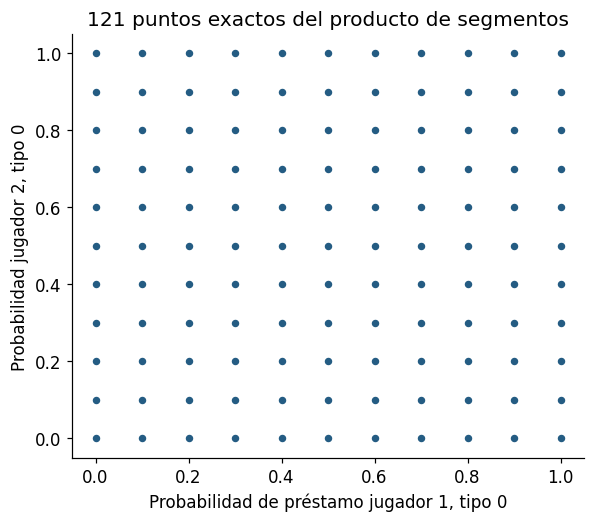

Puntos verificados: 121 ; máximo regret: 0.0


In [6]:
sampled=[]
for i in range(11):
    for j in range(11):
        point=(F(i,10),1-F(i,10),F(j,10),1-F(j,10))
        r=exact_regret(g,point)
        assert r==0 and family.left.contains(point[:2]) and family.right.contains(point[2:])
        sampled.append(dict(x0=float(point[0]),x1=float(point[2]),regret=float(r)))
family_samples=pd.DataFrame(sampled)
fig,ax=plt.subplots(figsize=(6,5))
ax.scatter(family_samples.x0,family_samples.x1,color='#245C83',s=15)
ax.set(xlabel='Probabilidad de préstamo jugador 1, tipo 0',ylabel='Probabilidad jugador 2, tipo 0',title='121 puntos exactos del producto de segmentos')
plt.show()
print('Puntos verificados:',len(family_samples),'; máximo regret:',family_samples.regret.max())

### Consecuencia para estabilidad
Una perturbación pequeña puede cambiar la dimensión del conjunto de forma discontinua. La distancia a un perfil elegido no resume esa inestabilidad geométrica. El cálculo racional depende de los valores decimales exactos de entrada y está acotado a dos jugadores y dos tipos.